In [1]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const
import pandas as pd

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt

from asymmetric_uncertainty_mod import a_u
from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared
from plotting import savefig, paper_plot
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
reflex_clean, variances = load_data_and_var()
reflex_clean.head()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


,OName,Name,L500,z_y,MSZ,e_MSZ,E_MSZ,L_err
2,RXCJ0003.8+0203,A2700,0.846881,0.0924,2.238774,0.301448,0.282160,0.136707
3,RXCJ0006.0-3443,A2721,1.809494,0.1147,4.001657,0.226974,0.248869,0.211627
6,RXCJ0011.3-2851,A2734,1.086002,0.0620,2.606369,0.188038,0.182667,0.086428
9,RXCJ0013.6-1930,A0013,1.236332,0.0940,2.756623,0.245311,0.233331,0.124160
10,RXCJ0014.3-6604,A2746,2.827248,0.1599,3.030337,0.347930,0.328876,0.313974


In [3]:
nfws_werr = generate_nfws_from_combined_dataset_werr(reflex_clean, variances)

In [4]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

In [6]:
[n.z for n in nfws_werr]

[0.232, 0.0924, 0.1147, 0.062, 0.094]

In [7]:
test_nfw = nfws_werr[1]

In [10]:
print(test_nfw.M500, test_nfw.R500)

223877399999999.94 (+28215999999999.996, -30144799999999.996) 0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)


In [21]:
G_conv = (const.G).to(u.Mpc*u.cm**2/(u.Msun*u.s**2)).value

In [22]:
def vel(nfw):
    return np.sqrt(G_conv * nfw.M500/(nfw.R500)) # returns in cm/s

In [23]:
print(vel(test_nfw))

103638854.67862509 (+6932745.86946993, -7309148.677778905)


In [33]:
rs = test_nfw.rvals * (u.cm/u.Mpc).to(1)
print(rs[-1])

0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)


In [37]:
test_nfw.rho_tot(rs)[-1]

In [41]:
((u.GeV/u.cm**3)/(u.Msun/u.Mpc**3)).to(1, equivalencies = u.mass_energy())

UnitConversionError: 'GeV Mpc3 / (cm3 solMass)' (specific energy) and '' (dimensionless) are not convertible

In [42]:
u.Msun.to(u.GeV)

1.1154161350360071e+57

In [43]:
u.Mpc.to(u.cm)

3.085677581491367e+24

In [54]:
u.s.to(u.Gyr)

3.168808781402895e-17

In [80]:
rho500 = test_nfw.rho_tot(rs)[-1]
rho500

In [97]:
def interaction_rate(mx, s0, nfw):
    rs = nfw.rvals * (u.cm/u.Mpc).to(1) # units Mpc
    rho500 = nfw.rho_tot(rs)[-1].value
    n500 = rho500/mx * u.Msun.to(u.GeV) / u.Mpc.to(u.cm)**3# units 1/cm**3
    return n500*vel(nfw).value*s0 / u.s.to(u.Gyr)# units 1/s

In [64]:
mxs = np.logspace(-6, 1)
s0 = 1e-25

Text(0, 0.5, 'interaction rate')

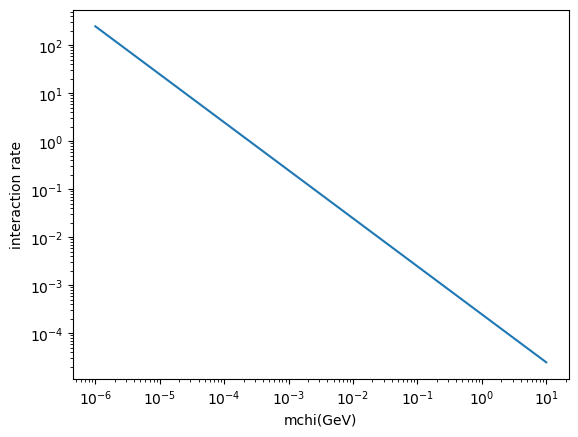

In [68]:
plt.loglog(mxs, np.array([interaction_rate(m, s0, test_nfw) for m in mxs]))

plt.xlabel('mchi(GeV)')
plt.ylabel('interaction rate')
# interaction rate higher for low mx because higher dm particle number density

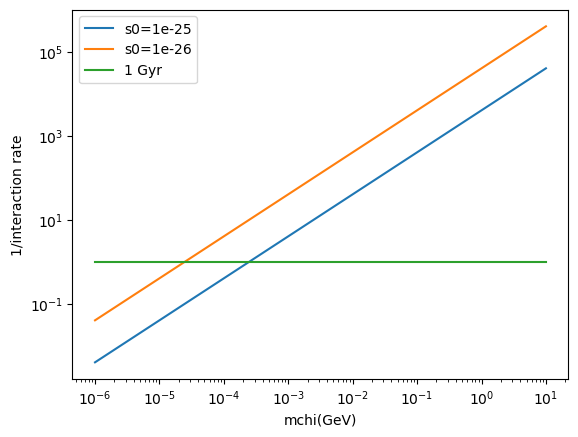

In [75]:
plt.loglog(mxs, 1./np.array([interaction_rate(m, s0, test_nfw) for m in mxs]), label=f's0={s0}')
plt.plot(mxs,1./np.array([interaction_rate(m, 1e-26, test_nfw) for m in mxs]), label='s0=1e-26')

plt.plot([mxs[0], mxs[-1]], [1, 1], label='1 Gyr')
plt.xlabel('mchi(GeV)')
plt.ylabel('1/interaction rate')
plt.legend()


In [149]:
import matplotlib.colors as colors
import matplotlib.patches as mpatches

# Create a grid of mx and s0 values
mx_values = np.logspace(-6, 1, 100)  # Avoid zero to prevent division by zero
s0_values = np.logspace(-30, -20, 100)  # Avoid zero to prevent division by zero
mx_grid, s0_grid = np.meshgrid(mx_values, s0_values)

# Compute the interaction rate for each combination of mx and s0
#interaction_rate_values = interaction_rate(mx_grid, s0_grid, test_nfw)

interaction_rate_values = np.zeros_like(mx_grid)
for i in range(mx_grid.shape[0]):
    for j in range(mx_grid.shape[1]):
        interaction_rate_values[i, j] = interaction_rate(mx_grid[i, j], s0_grid[i, j], test_nfw)


# Determine where 1 / interaction_rate > 1
condition = (1 / interaction_rate_values) > 1


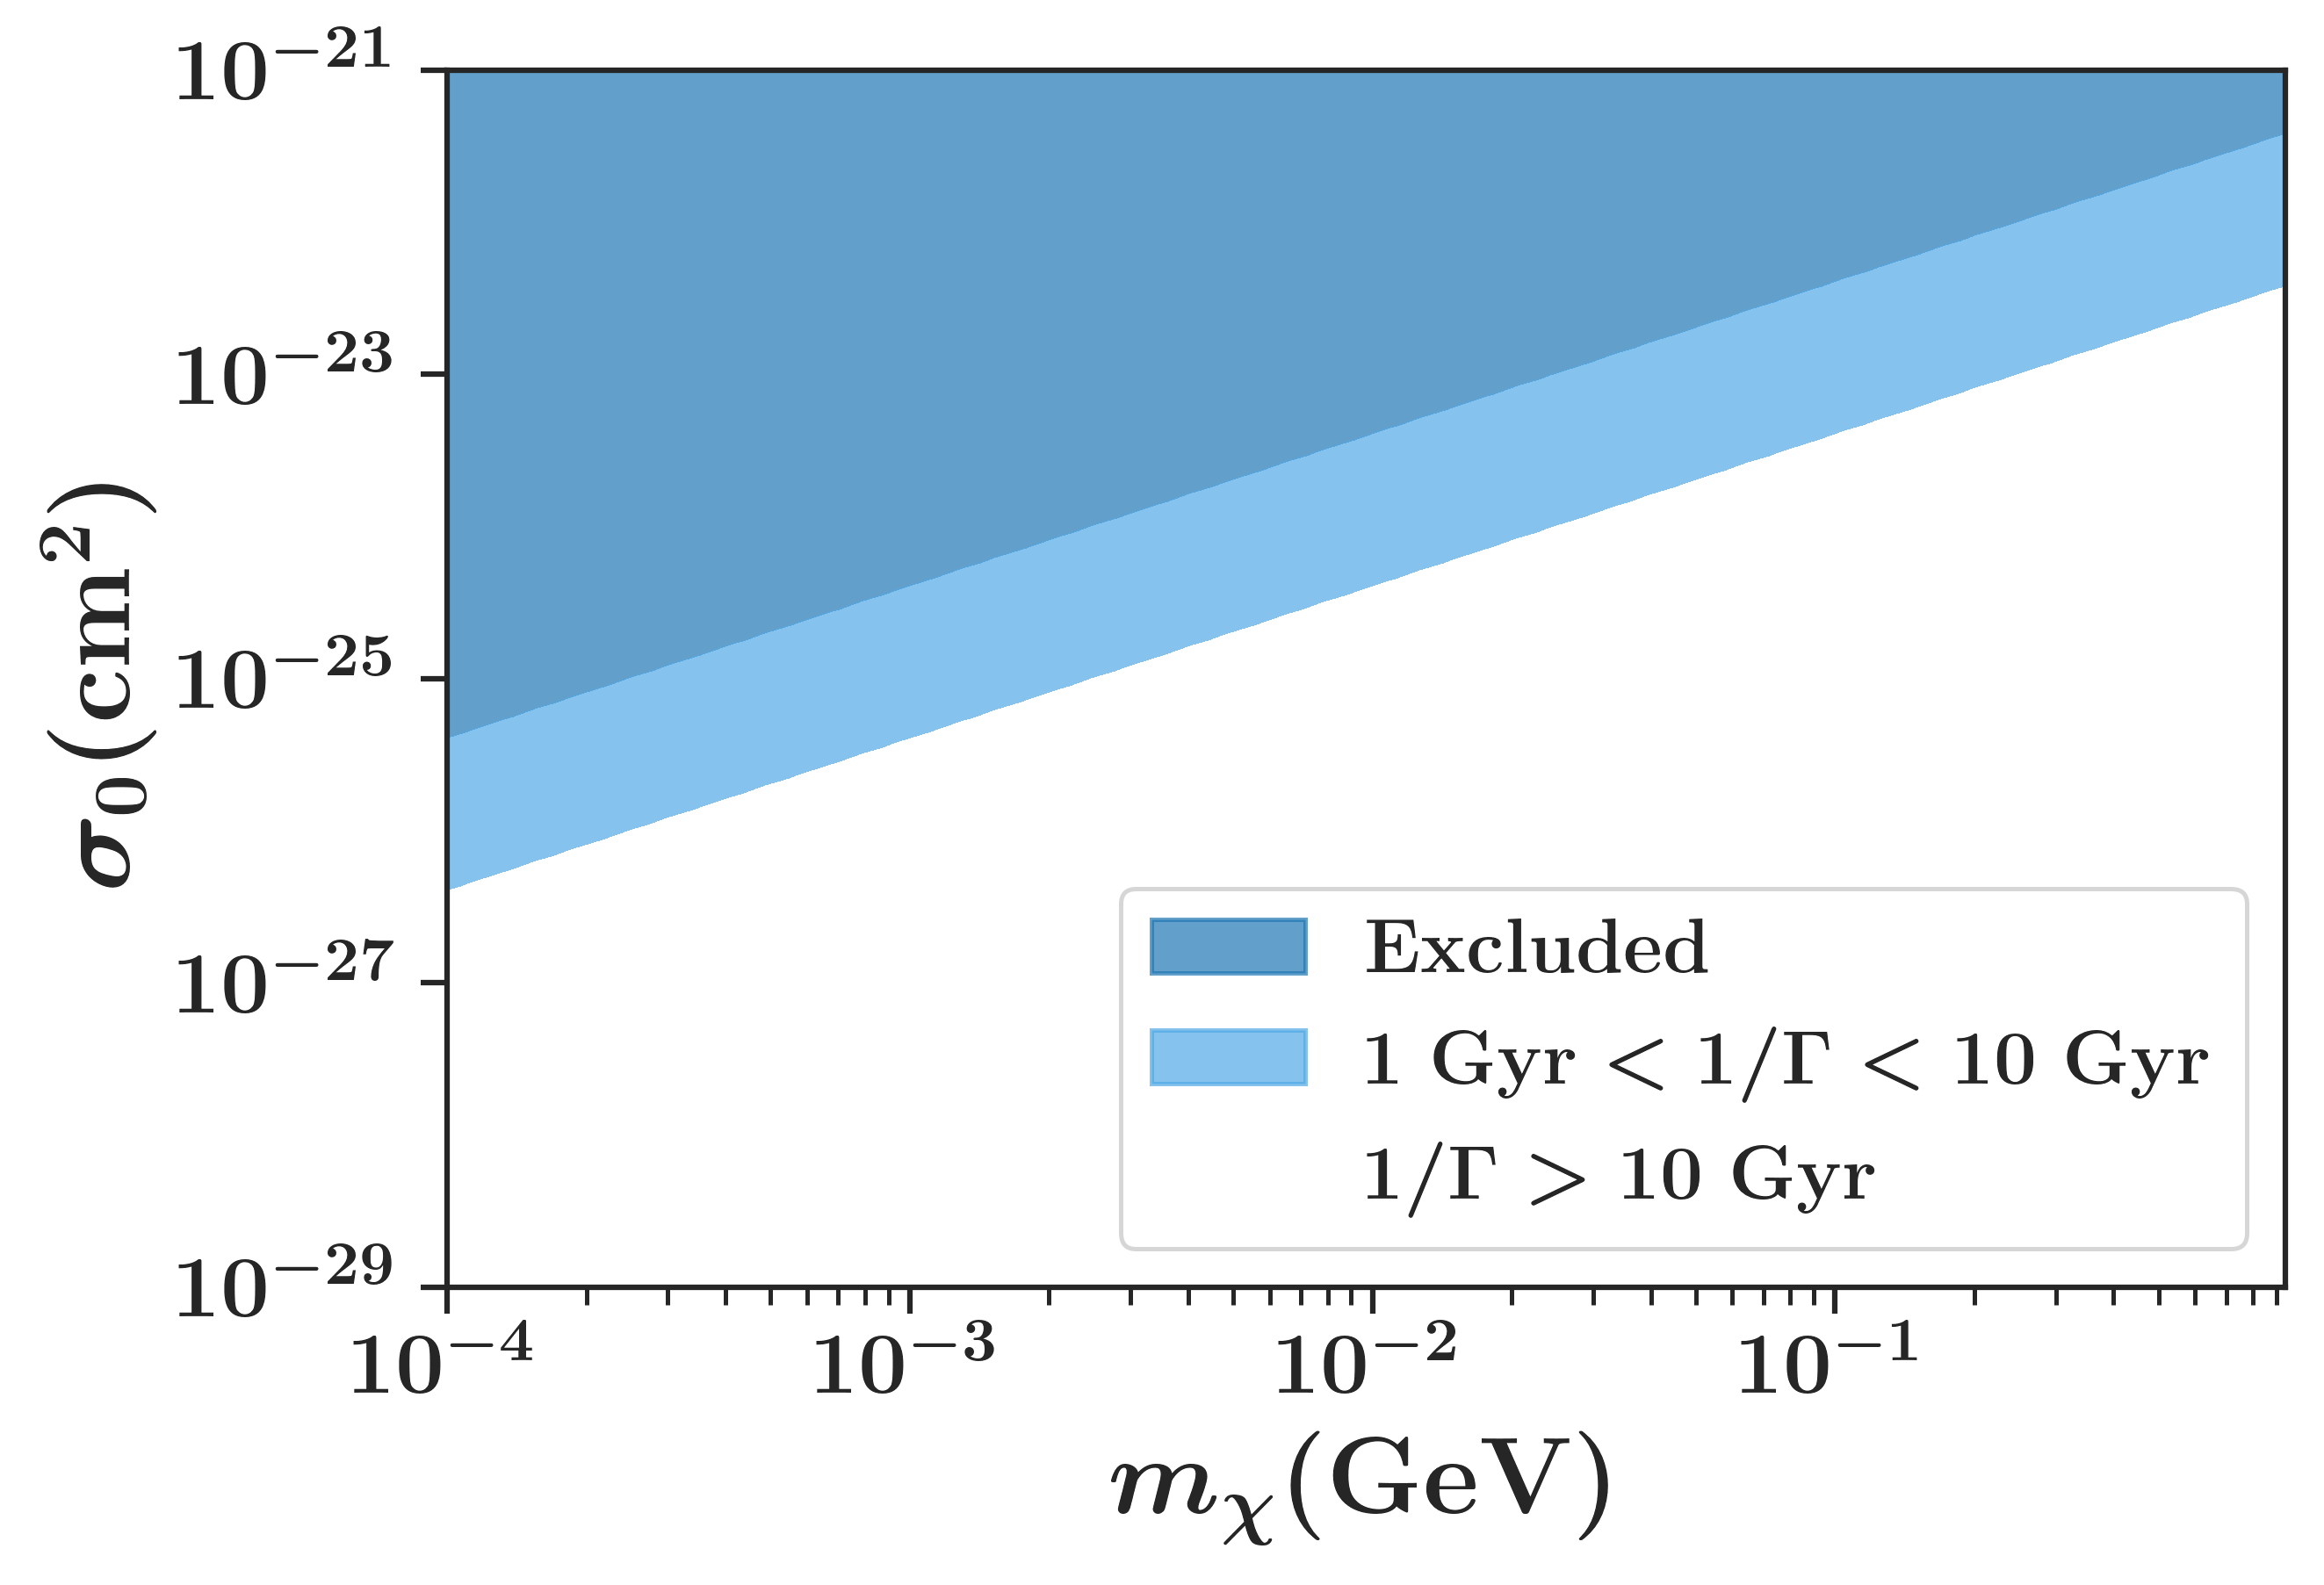

In [158]:
paper_plot()
# Plot the parameter space
plt.figure(dpi=450)
#plt.contourf(mx_grid, s0_grid, condition, levels=[0, 1], colors=['blue', 'white'])
plt.contourf(mx_grid, s0_grid, 1/interaction_rate_values, levels=[0,1, 10], colors=['#1f77b4','#51a9e6', 'white'], norm=colors.LogNorm(), alpha=0.7)
legend_patches = [mpatches.Patch(color='#1f77b4', label=f'$\mathrm{{Excluded}}$', alpha=0.7),
                   mpatches.Patch(color='#51a9e6', label=f'$\mathrm{{1~Gyr<1/\Gamma < 10~Gyr}}$', alpha=0.7),
                 mpatches.Patch(color='white', label=f'$\mathrm{{1/\Gamma > 10~Gyr}}$')]
plt.legend(handles=legend_patches, fontsize='14', loc='lower right')

#plt.colorbar(label='Interaction Rate')
#plt.colorbar(label='Condition (1 / interaction_rate > 1)')
plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
#plt.title('Parameter Space where 1 / interaction_rate(mx, s0, nfw) > 1')
plt.xscale('log')
plt.yscale('log')
plt.tick_params(axis='both', labelsize='16')

plt.xlim(1e-4, const.m_p.to(u.GeV).value)
plt.ylim(1e-29, 1e-21)
plt.show()


In [99]:
interaction_rate_values

array([[2.47764341e-03, 2.10538600e-03, 1.78905899e-03, ...,
        3.43125459e-10, 2.91572038e-10, 2.47764341e-10],
       [6.34164705e-03, 5.38883637e-03, 4.57918222e-03, ...,
        8.78246057e-10, 7.46292604e-10, 6.34164705e-10],
       [1.62317495e-02, 1.37929849e-02, 1.17206363e-02, ...,
        2.24791287e-09, 1.91017168e-09, 1.62317495e-09],
       ...,
       [3.78191942e+16, 3.21369902e+16, 2.73085178e+16, ...,
        5.23752866e+09, 4.45060798e+09, 3.78191942e+09],
       [9.68000399e+16, 8.22561665e+16, 6.98974601e+16, ...,
        1.34057056e+10, 1.13915444e+10, 9.68000399e+09],
       [2.47764341e+17, 2.10538600e+17, 1.78905899e+17, ...,
        3.43125459e+10, 2.91572038e+10, 2.47764341e+10]])

In [100]:
1/interaction_rate_values

array([[4.03609331e+02, 4.74972285e+02, 5.58953062e+02, ...,
        2.91438590e+09, 3.42968416e+09, 4.03609331e+09],
       [1.57687741e+02, 1.85568819e+02, 2.18379604e+02, ...,
        1.13863307e+09, 1.33995700e+09, 1.57687741e+09],
       [6.16076535e+01, 7.25006230e+01, 8.53195997e+01, ...,
        4.44857100e+08, 5.23513152e+08, 6.16076535e+08],
       ...,
       [2.64415999e-17, 3.11167908e-17, 3.66186113e-17, ...,
        1.90929743e-10, 2.24688403e-10, 2.64415999e-10],
       [1.03305743e-17, 1.21571433e-17, 1.43066715e-17, ...,
        7.45951037e-11, 8.77844097e-11, 1.03305743e-10],
       [4.03609331e-18, 4.74972285e-18, 5.58953062e-18, ...,
        2.91438590e-11, 3.42968416e-11, 4.03609331e-11]])

In [101]:
mx_values

array([1.00000000e-06, 1.17681195e-06, 1.38488637e-06, 1.62975083e-06,
       1.91791026e-06, 2.25701972e-06, 2.65608778e-06, 3.12571585e-06,
       3.67837977e-06, 4.32876128e-06, 5.09413801e-06, 5.99484250e-06,
       7.05480231e-06, 8.30217568e-06, 9.77009957e-06, 1.14975700e-05,
       1.35304777e-05, 1.59228279e-05, 1.87381742e-05, 2.20513074e-05,
       2.59502421e-05, 3.05385551e-05, 3.59381366e-05, 4.22924287e-05,
       4.97702356e-05, 5.85702082e-05, 6.89261210e-05, 8.11130831e-05,
       9.54548457e-05, 1.12332403e-04, 1.32194115e-04, 1.55567614e-04,
       1.83073828e-04, 2.15443469e-04, 2.53536449e-04, 2.98364724e-04,
       3.51119173e-04, 4.13201240e-04, 4.86260158e-04, 5.72236766e-04,
       6.73415066e-04, 7.92482898e-04, 9.32603347e-04, 1.09749877e-03,
       1.29154967e-03, 1.51991108e-03, 1.78864953e-03, 2.10490414e-03,
       2.47707636e-03, 2.91505306e-03, 3.43046929e-03, 4.03701726e-03,
       4.75081016e-03, 5.59081018e-03, 6.57933225e-03, 7.74263683e-03,
      

In [102]:
s0_values

array([1.00000000e-30, 2.55954792e-30, 6.55128557e-30, 1.67683294e-29,
       4.29193426e-29, 1.09854114e-28, 2.81176870e-28, 7.19685673e-28,
       1.84206997e-27, 4.71486636e-27, 1.20679264e-26, 3.08884360e-26,
       7.90604321e-26, 2.02358965e-25, 5.17947468e-25, 1.32571137e-24,
       3.39322177e-24, 8.68511374e-24, 2.22299648e-23, 5.68986603e-23,
       1.45634848e-22, 3.72759372e-22, 9.54095476e-22, 2.44205309e-21,
       6.25055193e-21, 1.59985872e-20, 4.09491506e-20, 1.04811313e-19,
       2.68269580e-19, 6.86648845e-19, 1.75751062e-18, 4.49843267e-18,
       1.15139540e-17, 2.94705170e-17, 7.54312006e-17, 1.93069773e-16,
       4.94171336e-16, 1.26485522e-15, 3.23745754e-15, 8.28642773e-15,
       2.12095089e-14, 5.42867544e-14, 1.38949549e-13, 3.55648031e-13,
       9.10298178e-13, 2.32995181e-12, 5.96362332e-12, 1.52641797e-11,
       3.90693994e-11, 1.00000000e-10])

In [104]:
interaction_rate_values = interaction_rate(mx_grid, s0_grid, test_nfw)
interaction_rate_values

array([[2.47764341e-03, 2.10538600e-03, 1.78905899e-03, ...,
        3.43125459e-10, 2.91572038e-10, 2.47764341e-10],
       [6.34164705e-03, 5.38883637e-03, 4.57918222e-03, ...,
        8.78246057e-10, 7.46292604e-10, 6.34164705e-10],
       [1.62317495e-02, 1.37929849e-02, 1.17206363e-02, ...,
        2.24791287e-09, 1.91017168e-09, 1.62317495e-09],
       ...,
       [3.78191942e+16, 3.21369902e+16, 2.73085178e+16, ...,
        5.23752866e+09, 4.45060798e+09, 3.78191942e+09],
       [9.68000399e+16, 8.22561665e+16, 6.98974601e+16, ...,
        1.34057056e+10, 1.13915444e+10, 9.68000399e+09],
       [2.47764341e+17, 2.10538600e+17, 1.78905899e+17, ...,
        3.43125459e+10, 2.91572038e+10, 2.47764341e+10]])

In [105]:
1/interaction_rate_values

array([[4.03609331e+02, 4.74972285e+02, 5.58953062e+02, ...,
        2.91438590e+09, 3.42968416e+09, 4.03609331e+09],
       [1.57687741e+02, 1.85568819e+02, 2.18379604e+02, ...,
        1.13863307e+09, 1.33995700e+09, 1.57687741e+09],
       [6.16076535e+01, 7.25006230e+01, 8.53195997e+01, ...,
        4.44857100e+08, 5.23513152e+08, 6.16076535e+08],
       ...,
       [2.64415999e-17, 3.11167908e-17, 3.66186113e-17, ...,
        1.90929743e-10, 2.24688403e-10, 2.64415999e-10],
       [1.03305743e-17, 1.21571433e-17, 1.43066715e-17, ...,
        7.45951037e-11, 8.77844097e-11, 1.03305743e-10],
       [4.03609331e-18, 4.74972285e-18, 5.58953062e-18, ...,
        2.91438590e-11, 3.42968416e-11, 4.03609331e-11]])

In [108]:
(1 / interaction_rate_values) > 1

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])